# 3. Detectability in Astrophysical Populations

In [1]:
import numpy as np

import sys
sys.path.append("../emri_tools")
from file_handling import load_population, load_hdf5_pop, load_hdf5

import matplotlib.pyplot as plt
from matplotlib.patches import ConnectionPatch, Patch
from seaborn import color_palette
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "font.serif": "Computer Modern",
    "text.latex.preamble": r"\usepackage{amsfonts}",
    "font.size": 17,
    "axes.titlesize": 18,
    "axes.labelsize": 18,
    "legend.frameon": False
})

In [2]:
fap = 0.01

## 3.1. EMRI populations

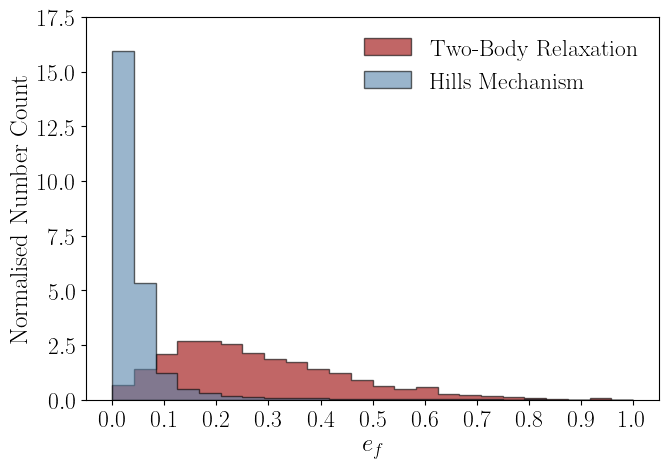

In [3]:
ef_rel, weight_rel = load_population("../populations/relaxation_channel.csv", weighted=True)
ef_hills, _ = load_population("../populations/hills_mechanism.csv", weighted=False)

bins = np.linspace(0, 1, 25)

plt.figure(figsize=(7,5))

plt.hist(ef_rel, weights=weight_rel, bins=bins, density=True, histtype="stepfilled", 
         alpha=0.6, edgecolor="black", linewidth=1, color="#990000", label="Two-Body Relaxation")
plt.hist(ef_hills, bins=bins, density=True, histtype="stepfilled", 
         alpha=0.6, color="#5785ab", edgecolor="black", linewidth=1, label="Hills Mechanism")

plt.xticks(np.arange(0, 1.01, 0.1))
plt.ylim([0, 17.5])
plt.xlabel(r"$e_f$")
plt.ylabel("Normalised Number Count")
plt.legend(loc="upper right")
plt.tight_layout()
#plt.savefig('../figures/3_populations_dist.pdf', bbox_inches='tight')
plt.show()

## 3.2. Load statistic data

In [4]:
filename = "../results/3_population_stats.h5"
df = load_hdf5_pop(filename)

## 3.3. Source detectability calibration

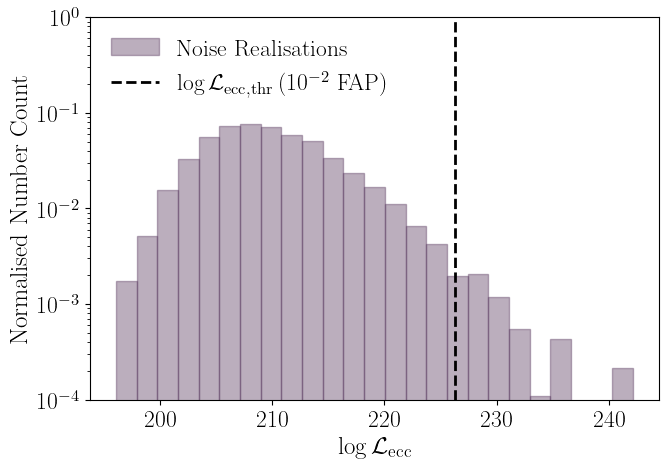

In [5]:
vals_logL_ecc = df["broad_noise_logL_ecc"].values

plt.figure(figsize=(7,5))

counts_ecc, bins_ecc, _ = plt.hist(vals_logL_ecc, bins=25, density=True, log=True, alpha=0.4, color="#56365C", edgecolor="#56365C", label="Noise Realisations")

median_logL_ecc_noise = np.median(vals_logL_ecc)

logL_ecc_thr = np.quantile(vals_logL_ecc, 1-fap)
plt.axvline(logL_ecc_thr, color="black", ls="--", lw=2, label=r"$\log \mathcal L_{\rm ecc, thr} \, (10^{-2} \textrm{ FAP})$")

plt.ylim([1e-4, 1e0])
plt.xlabel(r"$\log \mathcal L_{\rm ecc}$")
plt.ylabel("Normalised Number Count")

plt.legend(loc="upper left")
plt.tight_layout()
#plt.savefig('../figures/3_noise_realizations.pdf', bbox_inches='tight')
plt.show()

In [6]:
# Overall detectability
df["overall_detectable"] = (df["broad_ecc_signal_logL_ecc"] > logL_ecc_thr)

## 3.4. Eccentricity detectability calibration

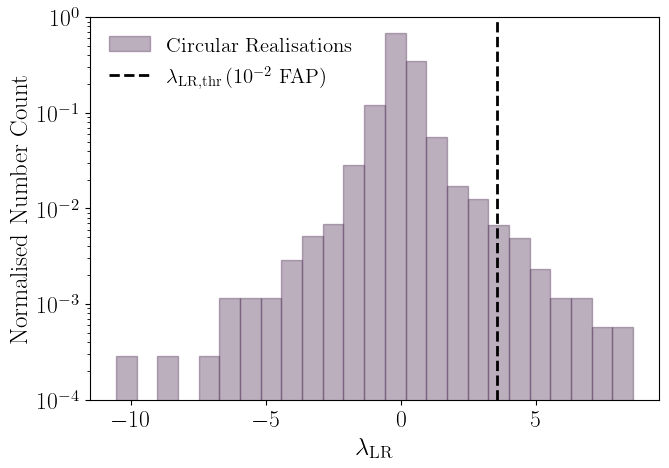

In [7]:
vals_lambda = df["narrow_circ_signal_lambda_LR"].values
mask_det = df["broad_ecc_signal_logL_ecc"].values > logL_ecc_thr
vals_lambda_det = vals_lambda[mask_det]

plt.figure(figsize=(7,5))

counts, bins, _ = plt.hist(vals_lambda_det, bins=25, density=True, log=True, alpha=0.4, color="#56365C", edgecolor="#56365C", label="Circular Realisations")

lambda_thr = np.quantile(vals_lambda_det, 1-fap)
plt.axvline(lambda_thr, color="black", ls="--", lw=2, label=r"$\lambda_{\rm LR, thr} \, (10^{-2} \textrm{ FAP})$")

plt.ylim([1e-4, 1e0])

plt.xlabel(r"$\lambda_{\rm LR}$")
plt.ylabel("Normalised Number Count")

plt.legend(loc="upper left", fontsize=15)
plt.tight_layout()
#plt.savefig('../figures/3_circular_realizations.pdf', bbox_inches='tight')
plt.show()

## 3.5. Thresholds' dependence on the adopted FAP

In [8]:
vals_fap = 10**np.linspace(-3, 0, 1000)
vals_logL_ecc_thr_fap = []
vals_lambda_thr_fap = []
    
for val_fap in vals_fap:
    
    logL_ecc_thr_fap = np.quantile(vals_logL_ecc, 1-val_fap)
    vals_logL_ecc_thr_fap += [logL_ecc_thr_fap]

    mask_det = df["broad_ecc_signal_logL_ecc"].values > logL_ecc_thr_fap
    vals_lambda_det = vals_lambda[mask_det]
    lambda_thr_fap = np.quantile(vals_lambda_det, 1-val_fap)
    vals_lambda_thr_fap += [lambda_thr_fap]

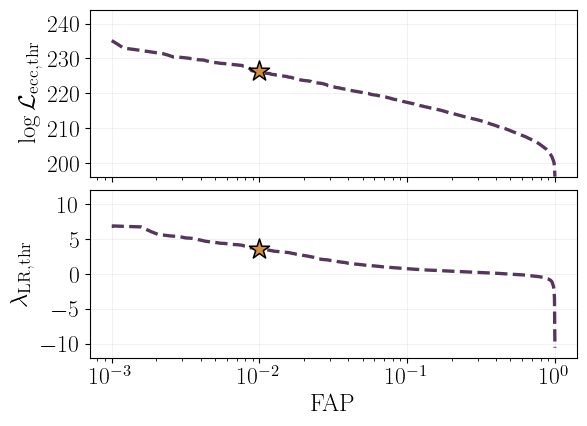

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(6.5, 4), sharex=True, gridspec_kw={"hspace": 0.08})

# Eccentric log-likelihood threshold
ax = axes[0]

ax.plot(vals_fap, vals_logL_ecc_thr_fap, "--", lw=2.4, color="#56365C")
ax.scatter(fap, logL_ecc_thr, s=230, marker="*", facecolors="#d78c3d",
           edgecolors="black", linewidths=1.1, zorder=2)

ax.set_ylim([196, 244])
ax.set_yticks(np.arange(200, 241, 10))
ax.set_ylabel(r"$\log \mathcal L_{\rm ecc,thr}$")
ax.grid(True, alpha=0.25, linewidth=0.5)

# Lambda threshold with narrow priors
ax = axes[1]

ax.plot(vals_fap, vals_lambda_thr_fap, "--", lw=2.4, color="#56365C")
ax.scatter(fap, lambda_thr, s=230, marker="*", facecolors="#d78c3d",
           edgecolors="black", linewidths=1.1, zorder=2)

ax.set_ylim([-12, 12])
ax.set_yticks(np.arange(-10, 11, 5))
ax.set_ylabel(r"$\lambda_{\rm LR,thr}$")
ax.grid(True, alpha=0.25, linewidth=0.5)

axes[1].set_xlabel("FAP")
axes[1].set_xscale("log")

axes[0].tick_params(axis="x", labelbottom=False)

fig.subplots_adjust(left=0.22, right=0.97, bottom=0.10, top=0.97, hspace=0.08)
#fig.savefig("../figures/3_fap_thresholds_det.pdf", bbox_inches="tight")
plt.show()

## 3.6. Source and eccentricity detectability in the populations

### a) Visualization

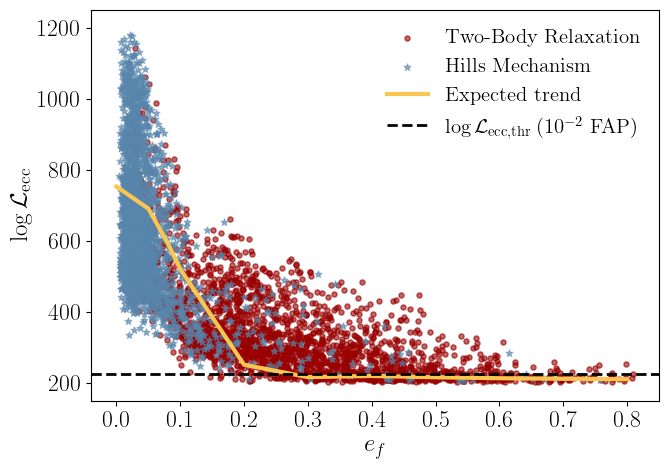

In [10]:
plt.figure(figsize=(7, 5))

for channel, color, marker, size in [("Two-Body Relaxation", "#990000", ".", 55),
                                     ("Hills Mechanism", "#5785ab", "*", 25)]:

    subset = df[(df["channel"] == channel)]

    plt.scatter(subset["ef_inj"], subset["broad_ecc_signal_logL_ecc"], label=channel,
                color=color, marker=marker, s=size, alpha=0.6)

filename = "../results/2_lambda_ef_20_mode.h5"
df_expected = load_hdf5(filename)

plt.plot(df_expected["ef_inj"], df_expected["logL_ecc"] + np.full_like(df_expected["logL_ecc"], median_logL_ecc_noise), label="Expected trend", c="#f9c74f", lw=3, ls="-")

plt.axhline(logL_ecc_thr, color="black", ls="--", lw=2, label=r"$\log \mathcal L_{\rm ecc, thr} \, (10^{-2} \textrm{ FAP})$")

plt.ylim([150, 1250])
plt.xticks(np.arange(0, 0.81, 0.1))

plt.xlabel(r"$e_f$")
plt.ylabel(r"$\log \mathcal L_{\rm ecc}$")
plt.legend(fontsize=15, loc="upper right")
plt.tight_layout()
#plt.savefig("../figures/3_logL_ecc_dist.png", dpi=600, bbox_inches="tight")
plt.show()

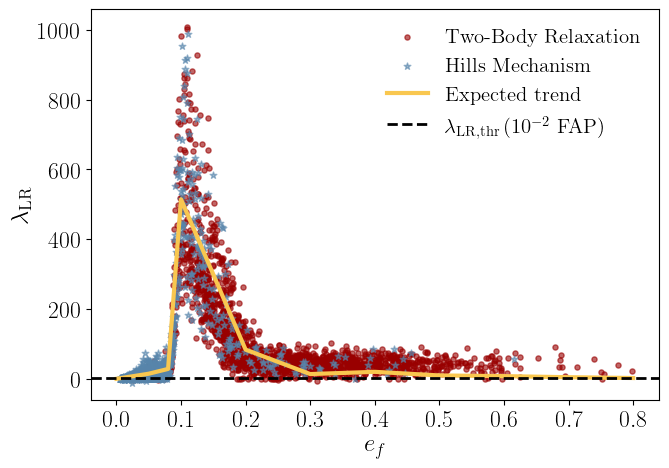

In [11]:
plt.figure(figsize=(7, 5))

for channel, color, marker, size in [("Two-Body Relaxation", "#990000", ".", 55),
                                     ("Hills Mechanism", "#5785ab", "*", 25)]:
    
    # Detectable sources
    subset = df[(df["channel"] == channel) & df["overall_detectable"]]
    plt.scatter(subset["ef_inj"], subset["narrow_ecc_signal_lambda_LR"], label=channel,
                color=color, marker=marker, s=size, alpha=0.6)

filename = "../results/2_lambda_ef_20_mode.h5"
df_expected = load_hdf5(filename)
plt.plot(df_expected["ef_inj"], df_expected["lambda_LR"], label="Expected trend", c="#f9c74f", lw=3, ls="-")

plt.axhline(lambda_thr, color="black", ls="--", lw=2, label=r"$\lambda_{\rm LR, thr} \, (10^{-2} \textrm{ FAP})$")

plt.ylim([-60, 1060])
plt.xticks(np.arange(0, 0.81, 0.1))

plt.xlabel(r"$e_f$")
plt.ylabel(r"$\lambda_{\rm LR}$")
plt.legend(fontsize=15)
plt.tight_layout()
#plt.savefig("../figures/3_lambda_narrow_dist.png", dpi=600, bbox_inches="tight")
plt.show()

### b) Final results

In [12]:
det_color = "gray"
non_det_color = "#bdbdbd"
ecc_det_color = "#a3c585"
non_ecc_det_color = "#ecd58d"

def plot_detectability(df, ax_pie, ax_bar, channel_title):
    """
    Plot overall detectability using the broad-prior eccentric model,
    followed by eccentricity detectability under narrow priors.
    Eccentricity fractions are conditional on overall detectability.
    """

    n_total = len(df)
    ax_pie.set_title(channel_title, fontsize=17.5, fontweight="bold", pad=10)

    overall = df["overall_detectable"]
    n_detectable = np.sum(overall)
    n_non_detectable = n_total - n_detectable

    # Overall-detectability pie

    wedges, _, autotexts = ax_pie.pie(
        [n_detectable, n_non_detectable],
        labels=["Detectable\nSources", "Non-Detectable\nSources"],
        colors=[det_color, non_det_color],
        startangle= 180 * n_detectable / n_total,
        counterclock=False,
        autopct=lambda pct: f"{pct:.1f}%" if pct > 0 else "",
        pctdistance=0.64,
        labeldistance=1.08,
        textprops={"fontsize": 16},
        wedgeprops={"edgecolor": "white", "linewidth": 1.1},
        radius=0.92,
    )

    if autotexts:
        autotexts[0].set_color("white")

        # Move the percentage of the small non-detectable fraction slightly upwards
        if n_non_detectable / n_total < 0.05:
            x, y = autotexts[1].get_position()
            autotexts[1].set_position((x + 0.2, y + 0.12))

    ax_pie.set_aspect("equal")
    ax_bar.set_xlim(-0.55, 1.55)
    ax_bar.set_xticks([])
    ax_bar.tick_params(axis="x", length=0, pad=10)
    ax_bar.set_yticks([])
    
    for spine in ax_bar.spines.values():
        spine.set_visible(False)
    
    if n_detectable == 0:
        ax_bar.text(0.5, 0.5, "No overall-detectable\nsources", ha="center", 
                    va="center", fontsize=16, transform=ax_bar.transAxes)
        return

    lr_values = df.loc[overall, "narrow_ecc_signal_lambda_LR"]

    ecc_detectable = lr_values > lambda_thr
    p_ecc = 100 * ecc_detectable.mean()
    p_ecc_not = 100 - p_ecc

    bar_width = 0.55

    # Bottom: eccentricity not detectable
    ax_bar.bar(0, p_ecc_not, width=bar_width, color=non_ecc_det_color,
               edgecolor="white", linewidth=1, zorder=3)

    # Top: eccentricity detectable
    ax_bar.bar(0, p_ecc, bottom=p_ecc_not, width=bar_width, color=ecc_det_color,
               edgecolor="white", linewidth=1, zorder=3)

    if p_ecc_not > 0:
        ax_bar.text(0, p_ecc_not / 2, rf"{p_ecc_not:.1f}\%",
                    ha="center", va="center", fontsize=16, fontweight="bold")

    if p_ecc > 0:
        ax_bar.text(0, p_ecc_not + p_ecc / 2, rf"{p_ecc:.1f}\%",
                    ha="center", va="center", fontsize=16, fontweight="bold")

    # Connect the detectable wedge to the full group of bars
    theta1, theta2 = wedges[0].theta1, wedges[0].theta2
    center, radius = wedges[0].center, wedges[0].r

    for theta, y_bar in [(theta1, 0), (theta2, 100)]:
        x_pie = center[0] + radius * np.cos(np.deg2rad(theta))
        y_pie = center[1] + radius * np.sin(np.deg2rad(theta))

        con = ConnectionPatch(
            xyA=(- bar_width / 2, y_bar),
            coordsA=ax_bar.transData,
            xyB=(x_pie, y_pie),
            coordsB=ax_pie.transData,
            linewidth=0.8,
            clip_on=False,
            zorder=1,
            color=det_color,
        )
        ax_bar.figure.add_artist(con)

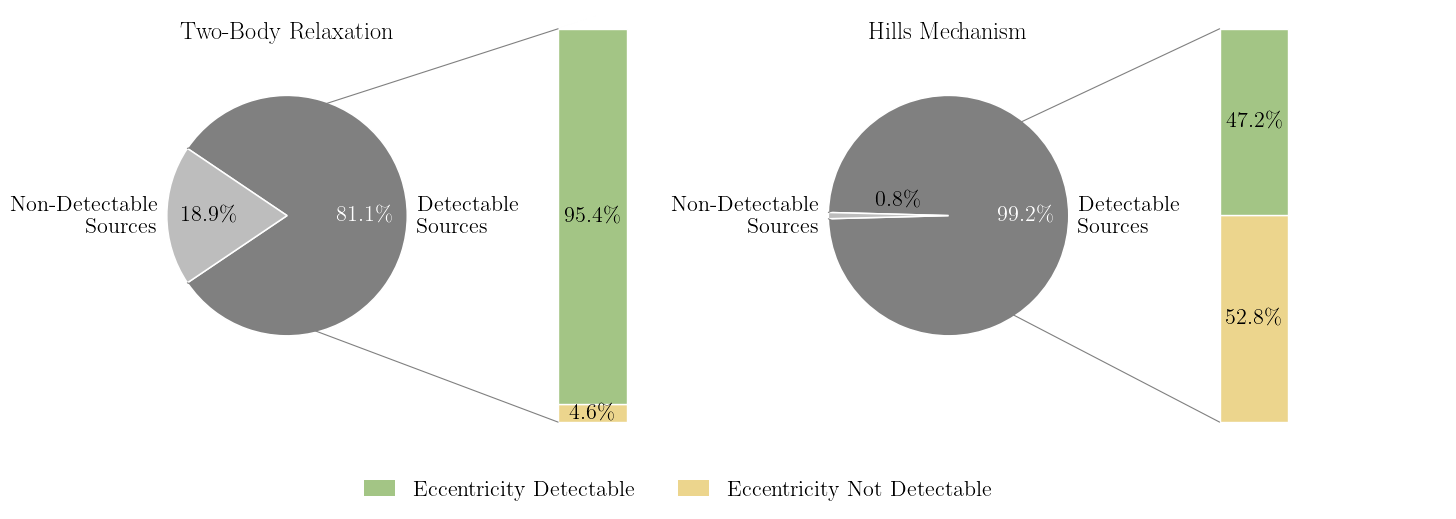

In [13]:
# Split the population by formation channel
df_relaxation = df[df["channel"] == "Two-Body Relaxation"]
df_hills = df[df["channel"] == "Hills Mechanism"]

fig = plt.figure(figsize=(13.5, 7))

outer_gs = fig.add_gridspec(1, 2, width_ratios=[1, 1], left=0.01, right=0.99, top=0.86, bottom=0.27, wspace=0.0)

gs_relax = outer_gs[0, 0].subgridspec(1, 2, width_ratios=[1, 0.8], wspace=0.25)
gs_hills = outer_gs[0, 1].subgridspec(1, 2, width_ratios=[1, 0.8], wspace=0.25)

ax_relax_pie = fig.add_subplot(gs_relax[0, 0])
ax_relax_bar = fig.add_subplot(gs_relax[0, 1])

ax_hills_pie = fig.add_subplot(gs_hills[0, 0])
ax_hills_bar = fig.add_subplot(gs_hills[0, 1])

plot_detectability(df_relaxation, ax_relax_pie, ax_relax_bar, "Two-Body Relaxation")
plot_detectability(df_hills, ax_hills_pie, ax_hills_bar, "Hills Mechanism")

legend_handles = [Patch(facecolor=ecc_det_color, label="Eccentricity Detectable"),
                  Patch(facecolor=non_ecc_det_color, label="Eccentricity Not Detectable")]

fig.legend(handles=legend_handles, loc="lower center", bbox_to_anchor=(0.42, 0.13), ncol=2,
           frameon=False, fontsize=16, handlelength=1.4, columnspacing=2.0)

plt.savefig("../figures/3_detectable_fractions.pdf", bbox_inches="tight", pad_inches=0)
plt.show()